# Student Performance Model Training

This notebook runs the project's end-to-end training pipeline. It compares and tunes multiple regressors using five-fold cross-validation, selects the model with the lowest cross-validation MAE, and evaluates that model on a held-out test set. The target is `math_score`; reading and writing scores are included as predictors.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

project_root = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "src" / "pipeline" / "train_pipeline.py").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the project root containing src/pipeline.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.pipeline.predict_pipeline import PredictionPipeline
from src.pipeline.train_pipeline import run_training_pipeline

In [2]:
training_result = run_training_pipeline()

cv_results = pd.DataFrame.from_dict(
    training_result.metrics["cv_results"],
    orient="index",
).sort_values("cv_mae")
display(cv_results)

print(f"Selected model: {training_result.best_model_name}")
print(f"Best parameters: {training_result.metrics['best_params']}")
print(f"Test MAE: {training_result.metrics['test_mae']:.2f}")
print(f"Test RMSE: {training_result.metrics['test_rmse']:.2f}")
print(f"Test R^2: {training_result.metrics['test_r2']:.3f}")
print(f"Saved model: {training_result.model_path}")

2026-11-13 19:51:31,370 | INFO | src.components.data_ingestion | Created train/test splits with 800 and 200 rows.


2026-11-13 19:51:31,383 | INFO | src.components.data_transformation | Prepared 2 numeric and 5 categorical features.


2026-11-13 19:51:31,555 | INFO | src.components.model_trainer | Linear regression: CV MAE 4.342, CV RMSE 5.412, parameters {}


2026-11-13 19:51:32,316 | INFO | src.components.model_trainer | Ridge: CV MAE 4.339, CV RMSE 5.411, parameters {'model__alpha': 1.0}


2026-11-13 19:51:32,959 | INFO | src.components.model_trainer | Decision tree: CV MAE 5.280, CV RMSE 6.582, parameters {'model__max_depth': 5, 'model__min_samples_leaf': 5}


2026-11-13 19:51:44,999 | INFO | src.components.model_trainer | Random forest: CV MAE 4.799, CV RMSE 5.989, parameters {'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__n_estimators': 250}


... (5 outputs left out)

2026-11-13 19:52:01,467 | INFO | src.components.model_trainer | Selected Ridge with CV MAE 4.339; test MAE 4.211, RMSE 5.390, R2 0.881.


2026-11-13 19:52:01,470 | INFO | src.pipeline.train_pipeline | Training pipeline completed. Model saved to D:\project_beg\artifacts\model.joblib


,cv_mae,cv_rmse,best_params
Ridge,4.339304,5.410606,{'model__alpha': 1.0}
Linear regression,4.342429,5.412153,{}
Support vector regression,4.593258,5.787479,"{'model__C': 10.0, 'model__epsilon': 0.1}"
XGBoost,4.613173,5.729022,"{'model__learning_rate': 0.1, 'model__max_dept..."
Extra trees,4.651416,5.776074,"{'model__max_depth': 10, 'model__min_samples_l..."
Random forest,4.798665,5.989424,"{'model__max_depth': None, 'model__min_samples..."
K-nearest neighbors,5.241301,6.576339,"{'model__n_neighbors': 20, 'model__weights': '..."
Decision tree,5.279548,6.582464,"{'model__max_depth': 5, 'model__min_samples_le..."
Mean baseline,11.963137,15.033661,{}


Selected model: Ridge
Best parameters: {'model__alpha': 1.0}
Test MAE: 4.21
Test RMSE: 5.39
Test R^2: 0.881
Saved model: D:\project_beg\artifacts\model.joblib


In [3]:
test_data = pd.read_csv(project_root / "artifacts" / "data" / "test.csv")
test_features = test_data.drop(columns="math_score")
predictions = PredictionPipeline(training_result.model_path).predict(test_features)
comparison = pd.DataFrame(
    {
        "actual": test_data["math_score"].to_numpy(),
        "predicted": predictions["predicted_math_score"].to_numpy(),
    }
)
display(comparison.head(10))

,actual,predicted
0,91,76.398746
1,53,58.843165
2,80,76.992035
3,74,76.806200
4,84,87.614981
5,81,78.916374
6,69,64.714615
7,54,53.044540
8,87,74.116489
9,51,49.365132


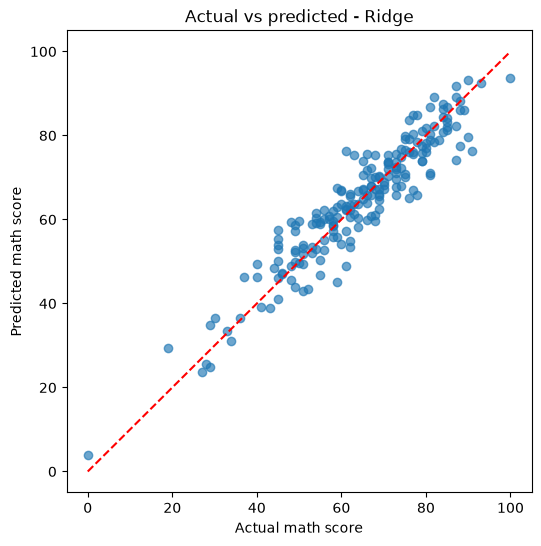

In [4]:
plt.figure(figsize=(6, 6))
plt.scatter(comparison["actual"], comparison["predicted"], alpha=0.65)
lower = min(comparison["actual"].min(), comparison["predicted"].min())
upper = max(comparison["actual"].max(), comparison["predicted"].max())
plt.plot([lower, upper], [lower, upper], color="red", linestyle="--")
plt.xlabel("Actual math score")
plt.ylabel("Predicted math score")
plt.title(f"Actual vs predicted - {training_result.best_model_name}")
plt.show()